# EN3160 Assignment 3 – Neural Networks
**Name:** Maldeniya P. A. D. G. R. (Ransara Maldeniya)  
**Index No:** 230390A  
**GitHub:**  https://github.com/ransara3/EN3160-Assignment-3-Neural-Networks.git 

Contents: Q1 manual two-layer dense network (CIFAR-10) · Q2 LeNet-5 vs modern CNN (MNIST) · Q3 ResNet18 transfer learning (hymenoptera)



In [10]:
import torch, torch.nn as nn, torch.optim as optim
import torchvision, torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np, time, copy, os, zipfile, urllib.request

torch.manual_seed(0); np.random.seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


# Question 1 – Two-layer dense network with manual backprop (CIFAR-10)

**Changes to Listing 1**
- **(a)** Added a hidden layer of 100 nodes with sigmoid activation: `x → [W1,b1] → sigmoid → [W2,b2] → logits`.
- **(b)** Replaced MSE with softmax cross-entropy: $L=-\frac1N\sum_i \log p_{i,y_i}$, with $p=\text{softmax}(z)$.
- **(c)** Train for 10 epochs; report train and test accuracy.

**Backprop derivation** (N = batch size, $h=\sigma(z_1)$, $z_2=hW_2+b_2$):
- $\partial L/\partial z_2 = (p - y_{onehot})/N$
- $\partial L/\partial W_2 = h^T\,\partial L/\partial z_2$, $\;\partial L/\partial b_2=\sum \partial L/\partial z_2$
- $\partial L/\partial h = \partial L/\partial z_2\,W_2^T$
- $\partial L/\partial z_1 = \partial L/\partial h \odot h(1-h)$ (sigmoid derivative)
- $\partial L/\partial W_1 = x^T\,\partial L/\partial z_1$, $\;\partial L/\partial b_1=\sum \partial L/\partial z_1$

The softmax + cross-entropy gradient simplifies to $p - y$, which is why no explicit softmax Jacobian is needed.

Epoch 1/10, Loss: 1.9836286301612853
Epoch 2/10, Loss: 1.7916364629268646
Epoch 3/10, Loss: 1.724887846827507
Epoch 4/10, Loss: 1.6850644433498383
Epoch 5/10, Loss: 1.6558335919380187
Epoch 6/10, Loss: 1.6320266543626785
Epoch 7/10, Loss: 1.6122231823205948
Epoch 8/10, Loss: 1.595042340517044
Epoch 9/10, Loss: 1.5796113295555114
Epoch 10/10, Loss: 1.5665409436225892


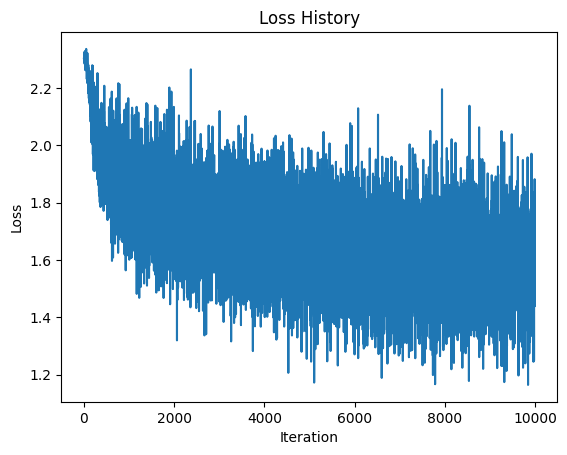

Training accuracy: 46.48%
Test accuracy: 44.73%


In [11]:

# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32   # Input size (flattened CIFAR-10 image size)
H = 100             # Hidden layer size
K = 10              # Output size (number of classes in CIFAR-10)
std = 1e-2

# Initialize weights and biases
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10     # epochs
lr = 5e-2           # Learning rate
lr_decay = 0.9      # Learning rate decay
reg = 0             # Regularization

loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]                          # Batch size
        x_train = inputs.view(Ntr, -1)                 # Flatten to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h = torch.sigmoid(x_train.mm(w1) + b1)         # hidden layer (sigmoid)
        y_pred = h.mm(w2) + b2                         # output logits
        probs = torch.softmax(y_pred, dim=1)

        # Cross-entropy loss with regularization
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(probs + 1e-12)) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (probs - y_train_onehot) / Ntr       # dL/d(logits)
        dw2 = h.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)
        dh = dy_pred.mm(w2.t())
        dz1 = dh * h * (1 - h)                         # sigmoid derivative
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        h = torch.sigmoid(x_train.mm(w1) + b1)
        y_train_pred = h.mm(w2) + b2

        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()
train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        h = torch.sigmoid(x_test.mm(w1) + b1)
        y_test_pred = h.mm(w2) + b2

        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()
test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

### Q1 Results and discussion

| Measure | Result |
|---|---:|
| Final training accuracy | 46.48% |
| Final test accuracy | 44.73% |
| Train-test accuracy gap | 1.75 percentage points |
| First-epoch training loss | 1.9836 |
| Final-epoch training loss | 1.5665 |

The average training loss decreased in every epoch, from 1.9836 to 1.5665. The improvement was larger at the start and became smaller towards the end. The decreasing learning rate also makes the later updates smaller. The batch-loss plot can still fluctuate because each batch contains different images.

The network classified 44.73% of the test images correctly. Training accuracy was only 1.75 percentage points higher, so there is no large generalisation gap after 10 epochs. However, the relatively low accuracy on both sets suggests that learning is still limited by the model or the training setup. A small gap alone does not mean the model performs well.

The sigmoid hidden layer lets the network learn nonlinear relationships between pixels. Without an activation between the dense layers, the two layers would be equivalent to a single linear transformation. Flattening the images also means the network does not explicitly use neighbouring pixels or share filters across positions, as a CNN does. This is a limitation for recognising objects in CIFAR-10. A direct comparison with a linear model or CNN would need separate experimental results.

Cross-entropy is suitable here because each image belongs to one of ten classes. Its gradient with respect to the logits is the difference between the predicted probabilities and the one-hot target, divided by the batch size. This gives a direct correction when the model assigns a low probability to the correct class. No MSE comparison was run, so these results do not establish a difference in training speed.

Sigmoid can slow learning when activations approach 0 or 1 because its derivative becomes small. The small initial weights help avoid very large initial activations, although saturation was not measured in this experiment. The learning rate of 0.05, decay of 0.9 and initial weight standard deviation of 0.01 are the settings used here; the notebook does not show a parameter search. Training for longer while monitoring a validation set would help check whether the network can improve further.


# Question 2 - LeNet-5 vs modern small CNN (MNIST)

Both models use Adam with a learning rate of 0.001, training batches of 128, 10 epochs and cross-entropy loss. MNIST inputs use the same normalisation for both models. Test evaluation uses batches of 1,000.

The following cells record training and test loss and accuracy after each epoch, plot the learning curves, and display a test-set confusion matrix for each model. Training metrics are collected during the parameter updates; test metrics are measured in evaluation mode after each epoch.


In [12]:
mnist_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
mn_train = torchvision.datasets.MNIST('./data', train=True,  download=True, transform=mnist_tf)
mn_test  = torchvision.datasets.MNIST('./data', train=False, download=True, transform=mnist_tf)
mn_trainloader = torch.utils.data.DataLoader(mn_train, batch_size=128, shuffle=True,  num_workers=2)
mn_testloader  = torch.utils.data.DataLoader(mn_test,  batch_size=1000, shuffle=False, num_workers=2)

### Q2(a) LeNet-5
Classic architecture: Conv(1→6, 5×5) → Tanh → AvgPool → Conv(6→16, 5×5) → Tanh → AvgPool → FC 400→120 → FC 120→84 → FC 84→10.  
`padding=2` in the first conv makes the 28×28 MNIST image behave like the original 32×32 input.

In [13]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5, padding=2), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5),           nn.Tanh(), nn.AvgPool2d(2))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16*5*5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10))
    def forward(self, x): return self.classifier(self.features(x))
print(LeNet5(), '\nParams:', sum(p.numel() for p in LeNet5().parameters()))

LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=400, out_features=120, bias=True)
    (2): Tanh()
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): Tanh()
    (5): Linear(in_features=84, out_features=10, bias=True)
  )
) 
Params: 61706


### Q2(b) Modern small CNN
Three conv blocks (Conv3×3 → **BatchNorm** → ReLU → MaxPool) with 32/64/128 channels, then **Dropout(0.3)** and a linear classifier.  
BatchNorm stabilises/accelerates training and allows higher learning rates; dropout regularises the classifier.

In [14]:
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1,32), block(32,64), block(64,128))   # 28->14->7->3
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128*3*3, 10))
    def forward(self, x): return self.classifier(self.features(x))
print(ModernCNN(), '\nParams:', sum(p.numel() for p in ModernCNN().parameters()))

ModernCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end

### Q2(c) Training, logging, plots, confusion matrices

In [15]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    loss_sum = correct = total = 0
    preds_all, labels_all = [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item()*len(y); correct += (out.argmax(1)==y).sum().item(); total += len(y)
            preds_all.append(out.argmax(1).cpu()); labels_all.append(y.cpu())
    return loss_sum/total, 100*correct/total, torch.cat(preds_all), torch.cat(labels_all)

def fit(model, epochs=10, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(); optimizer = optim.Adam(model.parameters(), lr=lr)
    log = {'train_loss':[], 'train_acc':[], 'test_loss':[], 'test_acc':[]}
    for ep in range(epochs):
        trl, tra, _, _ = run_epoch(model, mn_trainloader, criterion, optimizer)
        tel, tea, _, _ = run_epoch(model, mn_testloader, criterion)   # eval mode
        for k, v in zip(log, (trl, tra, tel, tea)): log[k].append(v)
        print(f'Epoch {ep+1:2d}/{epochs}  train loss {trl:.4f} acc {tra:.2f}% | test loss {tel:.4f} acc {tea:.2f}%')
    return model, log

def confusion_matrix(preds, labels, n=10):
    cm = torch.zeros(n, n, dtype=torch.int64)
    for t, p in zip(labels, preds): cm[t, p] += 1
    return cm.numpy()

def plot_logs(log, name):
    ep = range(1, len(log['train_loss'])+1)
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    ax[0].plot(ep, log['train_loss'], label='Train'); ax[0].plot(ep, log['test_loss'], label='Test'); ax[0].set_title(f'{name} – Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(ep, log['train_acc'], label='Train'); ax[1].plot(ep, log['test_acc'], label='Test'); ax[1].set_title(f'{name} – Accuracy (%)'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.tight_layout(); plt.show()

def plot_cm(cm, name):
    plt.figure(figsize=(6,5)); plt.imshow(cm, cmap='Blues'); plt.colorbar()
    for i in range(10):
        for j in range(10):
            plt.text(j, i, cm[i,j], ha='center', va='center', fontsize=7, color='white' if cm[i,j] > cm.max()/2 else 'black')
    plt.xticks(range(10)); plt.yticks(range(10)); plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'{name} – Confusion matrix (test)')
    plt.show()

=== LeNet-5 ===
Epoch  1/10  train loss 0.3321 acc 90.69% | test loss 0.1139 acc 96.51%
Epoch  2/10  train loss 0.0913 acc 97.25% | test loss 0.0603 acc 98.14%
Epoch  3/10  train loss 0.0615 acc 98.13% | test loss 0.0500 acc 98.43%
Epoch  4/10  train loss 0.0457 acc 98.61% | test loss 0.0451 acc 98.66%
Epoch  5/10  train loss 0.0373 acc 98.88% | test loss 0.0425 acc 98.73%
Epoch  6/10  train loss 0.0319 acc 99.02% | test loss 0.0442 acc 98.62%
Epoch  7/10  train loss 0.0252 acc 99.20% | test loss 0.0420 acc 98.68%
Epoch  8/10  train loss 0.0225 acc 99.28% | test loss 0.0381 acc 98.72%
Epoch  9/10  train loss 0.0189 acc 99.39% | test loss 0.0372 acc 98.88%
Epoch 10/10  train loss 0.0160 acc 99.53% | test loss 0.0389 acc 98.86%


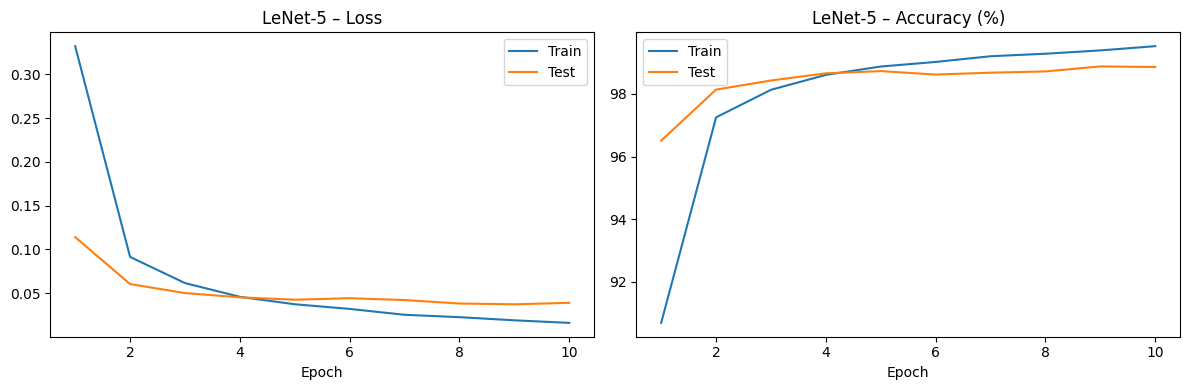

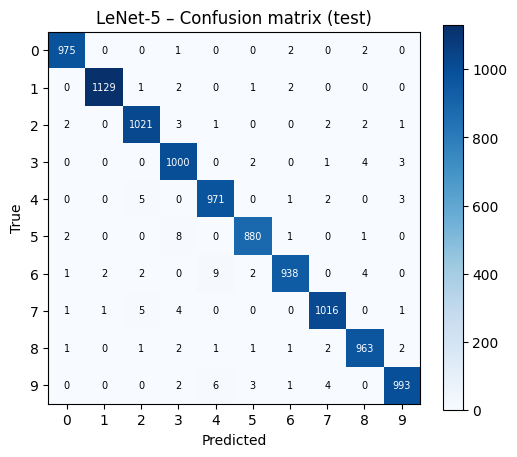

In [16]:
print('=== LeNet-5 ===')
lenet, log_lenet = fit(LeNet5())
plot_logs(log_lenet, 'LeNet-5')
_,_,p,l = run_epoch(lenet, mn_testloader, nn.CrossEntropyLoss())
cm_lenet = confusion_matrix(p, l); plot_cm(cm_lenet, 'LeNet-5')

=== Modern CNN (BN + Dropout) ===
Epoch  1/10  train loss 0.1410 acc 95.84% | test loss 0.0564 acc 98.15%
Epoch  2/10  train loss 0.0466 acc 98.56% | test loss 0.0515 acc 98.24%
Epoch  3/10  train loss 0.0334 acc 98.97% | test loss 0.0334 acc 98.86%
Epoch  4/10  train loss 0.0288 acc 99.11% | test loss 0.0202 acc 99.41%
Epoch  5/10  train loss 0.0217 acc 99.30% | test loss 0.0241 acc 99.18%
Epoch  6/10  train loss 0.0197 acc 99.38% | test loss 0.0276 acc 99.15%
Epoch  7/10  train loss 0.0176 acc 99.41% | test loss 0.0256 acc 99.22%
Epoch  8/10  train loss 0.0140 acc 99.56% | test loss 0.0216 acc 99.36%
Epoch  9/10  train loss 0.0135 acc 99.56% | test loss 0.0216 acc 99.34%
Epoch 10/10  train loss 0.0125 acc 99.56% | test loss 0.0236 acc 99.34%


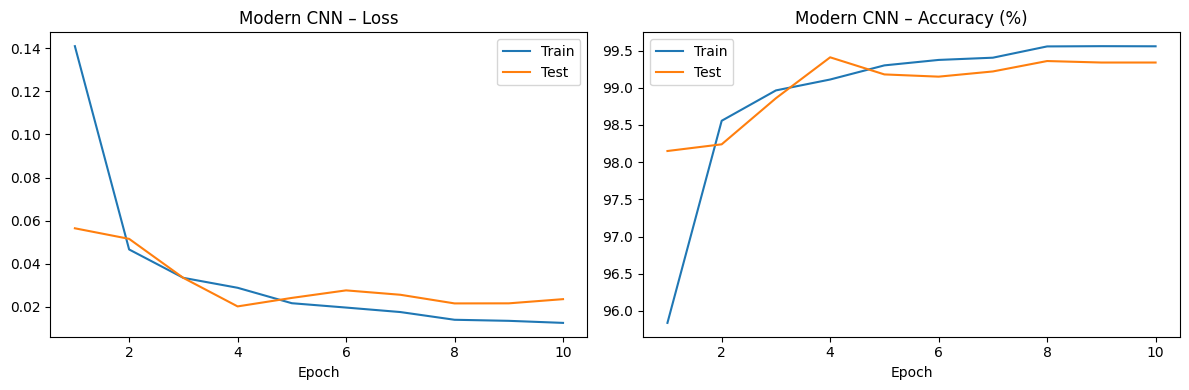

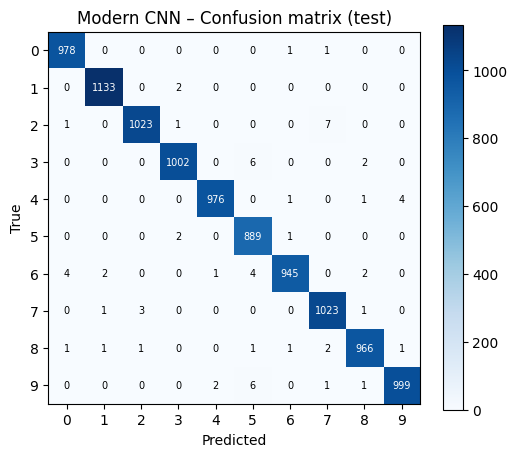

In [17]:
print('=== Modern CNN (BN + Dropout) ===')
modern, log_modern = fit(ModernCNN())
plot_logs(log_modern, 'Modern CNN')
_,_,p,l = run_epoch(modern, mn_testloader, nn.CrossEntropyLoss())
cm_modern = confusion_matrix(p, l); plot_cm(cm_modern, 'Modern CNN')

In [18]:
print(f"{'Model':<12}{'Train acc':>12}{'Test acc':>12}{'Test loss':>12}")
for n, lg in (('LeNet-5', log_lenet), ('Modern CNN', log_modern)):
    print(f"{n:<12}{lg['train_acc'][-1]:>11.2f}%{lg['test_acc'][-1]:>11.2f}%{lg['test_loss'][-1]:>12.4f}")
# most confused pairs
for n, cm in (('LeNet-5', cm_lenet), ('Modern CNN', cm_modern)):
    off = cm.copy(); np.fill_diagonal(off, 0); i, j = np.unravel_index(off.argmax(), off.shape)
    print(f'{n}: most common error – true {i} predicted as {j} ({off[i,j]} times)')

Model          Train acc    Test acc   Test loss
LeNet-5           99.53%      98.86%      0.0389
Modern CNN        99.56%      99.34%      0.0236
LeNet-5: most common error – true 6 predicted as 4 (9 times)
Modern CNN: most common error – true 2 predicted as 7 (7 times)


### Q2 Results and discussion

The following values are from the final epoch of each saved training run.

| Model | Train accuracy | Test accuracy | Train loss | Test loss | Parameters |
|---|---:|---:|---:|---:|---:|
| LeNet-5 | 99.53% | 98.86% | 0.0160 | 0.0389 | 61,706 |
| Modern CNN | 99.56% | 99.34% | 0.0125 | 0.0236 | 104,650 |

Both models performed well on MNIST. The modern CNN finished with a test accuracy of 99.34%, compared with 98.86% for LeNet-5. This is an improvement of 0.48 percentage points, or 48 fewer mistakes on the 10,000 test images: 66 errors instead of 114. Its final test loss was also lower, at 0.0236 compared with 0.0389.

The modern CNN learned faster in the early epochs. Its test accuracy reached 98.15% after one epoch, while LeNet-5 reached 96.51%. By epoch 4, the modern CNN had reached its highest recorded test accuracy of 99.41%. LeNet-5 improved more gradually and reached its highest recorded test accuracy of 98.88% at epoch 9. The modern model's ReLU activations avoid the positive-side saturation of Tanh, while BatchNorm normalises intermediate activations during training. These features can help optimisation, but the models also differ in depth, width and pooling, so the improvement cannot be attributed to one component alone. Both models used Adam.

Using the logged final-epoch values, the train-test accuracy gaps were 0.67 percentage points for LeNet-5 and 0.22 percentage points for the modern CNN. These are small gaps. However, training accuracy was accumulated while the weights were changing and, for the modern CNN, while dropout was active. Test accuracy was measured after the epoch in evaluation mode, with dropout disabled and BatchNorm using running statistics. The gaps therefore do not compare both datasets under exactly the same evaluation conditions. This also helps explain why test accuracy sometimes exceeded training accuracy.

LeNet-5's training loss fell from 0.3321 to 0.0160. Its test loss generally improved, but rose slightly from 0.0372 at epoch 9 to 0.0389 at epoch 10 while training loss continued falling. The modern CNN's training loss fell from 0.1410 to 0.0125, whereas its lowest test loss was 0.0202 at epoch 4 and its final test loss was 0.0236. The later epochs brought little improvement on the test set, with some signs of mild overfitting. Dropout reduces reliance on individual classifier inputs, but it does not guarantee that test loss will keep decreasing.

The confusion matrices show that LeNet-5's most frequent individual error was classifying a true **6 as 4**, which happened **9 times**. For the modern CNN, the most frequent error was classifying a true **2 as 7**, which happened **7 times**. Handwritten digits can have overlapping stroke patterns, which is a possible explanation, but inspecting the misclassified images would be needed to confirm it. These are directional errors, rather than counts summed across both directions of a digit pair.

LeNet-5 uses 61,706 parameters, while the modern CNN uses 104,650, about 1.70 times as many. The modern CNN gives better test accuracy in this run at the cost of a larger model. LeNet-5 still achieves 98.86% with fewer parameters. Execution times were not recorded, so the notebook does not establish how much faster either model runs.


# Question 3 – Transfer learning with ResNet18 (hymenoptera: ants vs bees)

Following the PyTorch transfer-learning tutorial, ResNet18 pre-trained on ImageNet-1K is adapted to the 2-class hymenoptera dataset (~244 train / 153 val images) in two ways:
- **(a) Fine-tuning:** replace the final FC layer (512→2) and train **all** layers (lr = 0.001, SGD momentum 0.9, StepLR ×0.1 every 7 epochs).
- **(b) Feature extractor:** freeze all pretrained layers (`requires_grad=False`), replace the FC layer, and train **only** the new FC layer.

In [19]:
# Download dataset (~45 MB)
url = 'https://download.pytorch.org/tutorial/hymenoptera_data.zip'
if not os.path.exists('hymenoptera_data'):
    urllib.request.urlretrieve(url, 'hymenoptera_data.zip')
    with zipfile.ZipFile('hymenoptera_data.zip') as z: z.extractall('.')
data_dir = 'hymenoptera_data'

data_tf = {
 'train': transforms.Compose([transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(), transforms.ToTensor(),
                              transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]),
 'val':   transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
                              transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])}
image_datasets = {x: torchvision.datasets.ImageFolder(os.path.join(data_dir, x), data_tf[x]) for x in ['train','val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4, shuffle=(x=='train'), num_workers=2) for x in ['train','val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train','val']}
class_names = image_datasets['train'].classes
print(dataset_sizes, class_names)

{'train': 244, 'val': 153} ['ants', 'bees']


In [20]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=15):
    best_wts, best_acc = copy.deepcopy(model.state_dict()), 0.0
    log = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}
    t0 = time.time()
    for ep in range(num_epochs):
        for phase in ['train','val']:
            model.train(phase=='train'); loss_sum = correct = 0
            for x, y in dataloaders[phase]:
                x, y = x.to(device), y.to(device)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase=='train'):
                    out = model(x); loss = criterion(out, y)
                    if phase=='train': loss.backward(); optimizer.step()
                loss_sum += loss.item()*x.size(0); correct += (out.argmax(1)==y).sum().item()
            if phase=='train': scheduler.step()
            el, ea = loss_sum/dataset_sizes[phase], 100*correct/dataset_sizes[phase]
            log[phase+'_loss'].append(el); log[phase+'_acc'].append(ea)
            if phase=='val' and ea > best_acc: best_acc, best_wts = ea, copy.deepcopy(model.state_dict())
        print(f"Epoch {ep+1:2d}/{num_epochs}  train loss {log['train_loss'][-1]:.4f} acc {log['train_acc'][-1]:.2f}% | val loss {log['val_loss'][-1]:.4f} acc {log['val_acc'][-1]:.2f}%")
    print(f'Time {time.time()-t0:.0f}s | best val acc {best_acc:.2f}%')
    model.load_state_dict(best_wts); return model, log, best_acc

def get_resnet(freeze):
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    if freeze:
        for p in m.parameters(): p.requires_grad = False
    m.fc = nn.Linear(m.fc.in_features, 2)   # new layer: requires_grad=True by default
    return m.to(device)

def plot_tl(log, name):
    ep = range(1, len(log['train_loss'])+1)
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    ax[0].plot(ep, log['train_loss'], label='Train'); ax[0].plot(ep, log['val_loss'], label='Val'); ax[0].set_title(f'{name} – Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(ep, log['train_acc'], label='Train'); ax[1].plot(ep, log['val_acc'], label='Val'); ax[1].set_title(f'{name} – Accuracy (%)'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.tight_layout(); plt.show()

### Q3(a) Fine-tuning (all layers trainable)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Epoch  1/15  train loss 0.5442 acc 72.54% | val loss 0.3152 acc 89.54%
Epoch  2/15  train loss 0.5310 acc 74.59% | val loss 0.2739 acc 88.24%
Epoch  3/15  train loss 0.3932 acc 84.02% | val loss 0.2928 acc 88.24%
Epoch  4/15  train loss 0.4015 acc 84.43% | val loss 0.2363 acc 91.50%
Epoch  5/15  train loss 0.3471 acc 86.48% | val loss 0.5583 acc 81.70%
Epoch  6/15  train loss 0.5236 acc 81.15% | val loss 0.3713 acc 86.93%
Epoch  7/15  train loss 0.4789 acc 81.97% | val loss 0.6564 acc 80.39%
Epoch  8/15  train loss 0.3571 acc 88.52% | val loss 0.2528 acc 91.50%
Epoch  9/15  train loss 0.3237 acc 85.66% | val loss 0.2385 acc 91.50%
Epoch 10/15  train loss 0.2735 acc 88.93% | val loss 0.2304 acc 92.16%
Epoch 11/15  train loss 0.2092 acc 90.16% | val loss 0.2222 acc 92.16%
Epoch 12/15  train loss 0.3229 acc 87.70% | val loss 0.2439 acc 91.50%
Epoch 13/15  train loss 0.3490 acc 86.89% | val loss 0.2201 acc 93.46%
Epoch 14/15  train loss 0.3646 acc 84.84% | val loss 0.1981 acc 92.16%
Epoch 

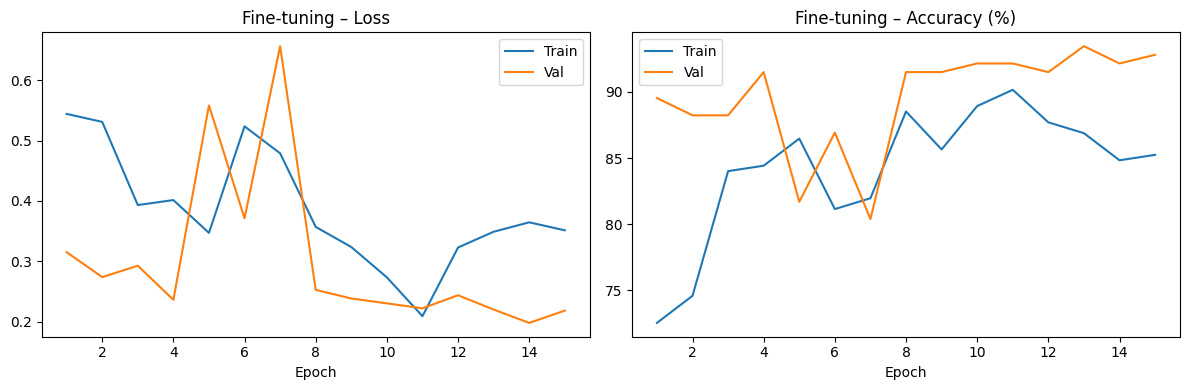

In [21]:
torch.manual_seed(0)
ft = get_resnet(freeze=False)
opt = optim.SGD(ft.parameters(), lr=0.001, momentum=0.9)
ft, log_ft, best_ft = train_model(ft, nn.CrossEntropyLoss(), opt, optim.lr_scheduler.StepLR(opt, 7, 0.1), num_epochs=15)
plot_tl(log_ft, 'Fine-tuning')

### Q3(b) Feature extractor (only final FC layer trainable)

Epoch  1/15  train loss 0.6072 acc 65.98% | val loss 0.2021 acc 94.12%
Epoch  2/15  train loss 0.5010 acc 72.13% | val loss 0.2871 acc 86.93%
Epoch  3/15  train loss 0.3930 acc 81.97% | val loss 0.2310 acc 90.20%
Epoch  4/15  train loss 0.3914 acc 84.84% | val loss 0.1825 acc 94.12%
Epoch  5/15  train loss 0.3995 acc 82.79% | val loss 0.3182 acc 86.93%
Epoch  6/15  train loss 0.5241 acc 76.23% | val loss 0.2443 acc 91.50%
Epoch  7/15  train loss 0.5625 acc 77.87% | val loss 0.3463 acc 88.24%
Epoch  8/15  train loss 0.3821 acc 85.25% | val loss 0.1750 acc 94.77%
Epoch  9/15  train loss 0.3467 acc 83.20% | val loss 0.1762 acc 94.12%
Epoch 10/15  train loss 0.2978 acc 87.70% | val loss 0.1970 acc 94.77%
Epoch 11/15  train loss 0.2524 acc 90.57% | val loss 0.1668 acc 94.77%
Epoch 12/15  train loss 0.3719 acc 84.84% | val loss 0.1785 acc 95.42%
Epoch 13/15  train loss 0.3900 acc 84.84% | val loss 0.2017 acc 92.81%
Epoch 14/15  train loss 0.4006 acc 82.38% | val loss 0.1693 acc 94.12%
Epoch 

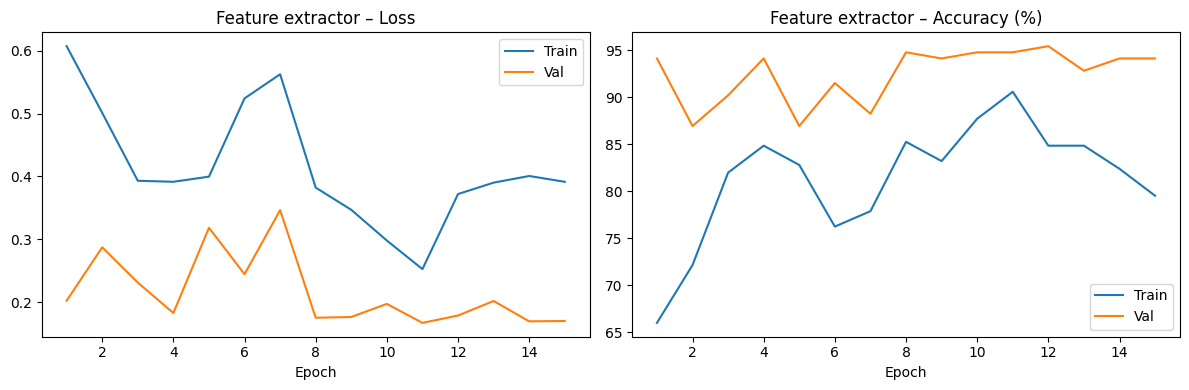

In [22]:
torch.manual_seed(0)
fe = get_resnet(freeze=True)
opt = optim.SGD(fe.fc.parameters(), lr=0.001, momentum=0.9)
fe, log_fe, best_fe = train_model(fe, nn.CrossEntropyLoss(), opt, optim.lr_scheduler.StepLR(opt, 7, 0.1), num_epochs=15)
plot_tl(log_fe, 'Feature extractor')

In [23]:
n_ft = sum(p.numel() for p in ft.parameters() if p.requires_grad)
n_fe = sum(p.numel() for p in fe.parameters() if p.requires_grad)
print(f"{'Method':<20}{'Final val acc':>15}{'Best val acc':>15}{'Trainable params':>20}")
print(f"{'Fine-tuning':<20}{log_ft['val_acc'][-1]:>14.2f}%{best_ft:>14.2f}%{11177538:>20,}")
print(f"{'Feature extractor':<20}{log_fe['val_acc'][-1]:>14.2f}%{best_fe:>14.2f}%{1026:>20,}")

Method                Final val acc   Best val acc    Trainable params
Fine-tuning                  92.81%         93.46%          11,177,538
Feature extractor            94.12%         95.42%               1,026


### Q3 Results and discussion

| Method | Final val accuracy (epoch 15) | Best val accuracy | Trainable parameters | Training time |
|---|---:|---:|---:|---:|
| Fine-tuning | 92.81% | 93.46% | 11,177,538 | 161 s |
| Feature extractor | 94.12% | 95.42% | 1,026 | 127 s |

Feature extraction gave the better result in this run. Its best validation accuracy was 95.42% at epoch 12, compared with 93.46% at epoch 13 for fine-tuning. This difference of 1.96 percentage points corresponds to three images out of the 153 validation images: 146 correct predictions compared with 143. With such a small validation set, a few predictions can change the reported accuracy noticeably. Repeated runs would be needed to judge how consistent this advantage is.

The final-epoch accuracies were slightly lower than the best values for both methods. The training function restores the weights from the epoch with the highest validation accuracy, so the returned models use the best checkpoints rather than the epoch-15 weights. The final-epoch column describes the training log.

The pretrained features were already useful for separating ants and bees. The feature extractor reached 94.12% validation accuracy after the first epoch, while fine-tuning reached 89.54%. Training only the new classifier limits the number of adjustable parameters, which is helpful with just 244 training images. Fine-tuning allows all layers to adapt to the new task, but this extra flexibility did not give better validation accuracy here.

Both runs fluctuated during the early epochs. Fine-tuning dropped to 80.39% validation accuracy at epoch 7, then recovered to 91.50% at epoch 8. Feature extraction improved from 88.24% to 94.77% over the same epochs. These improvements followed the first scheduled learning-rate reduction, which made the updates smaller. The small dataset, training augmentation and batch size of four can also contribute to variation between epochs.

At epoch 15, training accuracy was 85.25% for fine-tuning and 79.51% for feature extraction, below their validation accuracies of 92.81% and 94.12%. The training images use random crops and horizontal flips, while validation uses a fixed centre crop. Training metrics are also collected while parameters are changing. These differences make the training task and measurement conditions different from validation, so the reversed gaps alone do not show that the models generalise unusually well.

Feature extraction took 127 seconds, compared with 161 seconds for fine-tuning, saving 34 seconds, or about 21% of the measured training time. It avoids gradient computation for the backbone parameters, but still needs a forward pass through ResNet18. Data loading and validation also contribute to runtime, so the much smaller trainable parameter count does not produce a proportional time reduction.

One detail of this implementation is that freezing parameters does not freeze BatchNorm's running statistics. The training function calls `model.train()` for both methods, so those statistics still update in the feature extractor even though only the final layer's weights are optimised. The backbone is therefore fixed in its learned parameters, but not in all of its stored state.
